<a href="https://colab.research.google.com/github/dilekmirac/dip/blob/main/hafta7_g%C3%B6rev6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2
import torch

print(f"OpenCV Versiyonu: {cv2.__version__}")
print(f"CUDA Kullanılabilir mi (PyTorch/GPU): {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"Aktif GPU Modeli: {torch.cuda.get_device_name(0)}")

OpenCV Versiyonu: 4.14.0
CUDA Kullanılabilir mi (PyTorch/GPU): True
Aktif GPU Modeli: Tesla T4


Sinyal 1 (f=50 Hz, A=12) -> Eşik: 1.488 | Temiz Sinyale Göre MSE: 0.0047
Sinyal 2 (f=30 Hz, A=5) -> Eşik: 0.609 | Temiz Sinyale Göre MSE: 0.0088
Toplam Sinyal (S1 + S2) -> Eşik: 1.483 | Temiz Sinyale Göre MSE: 0.0213


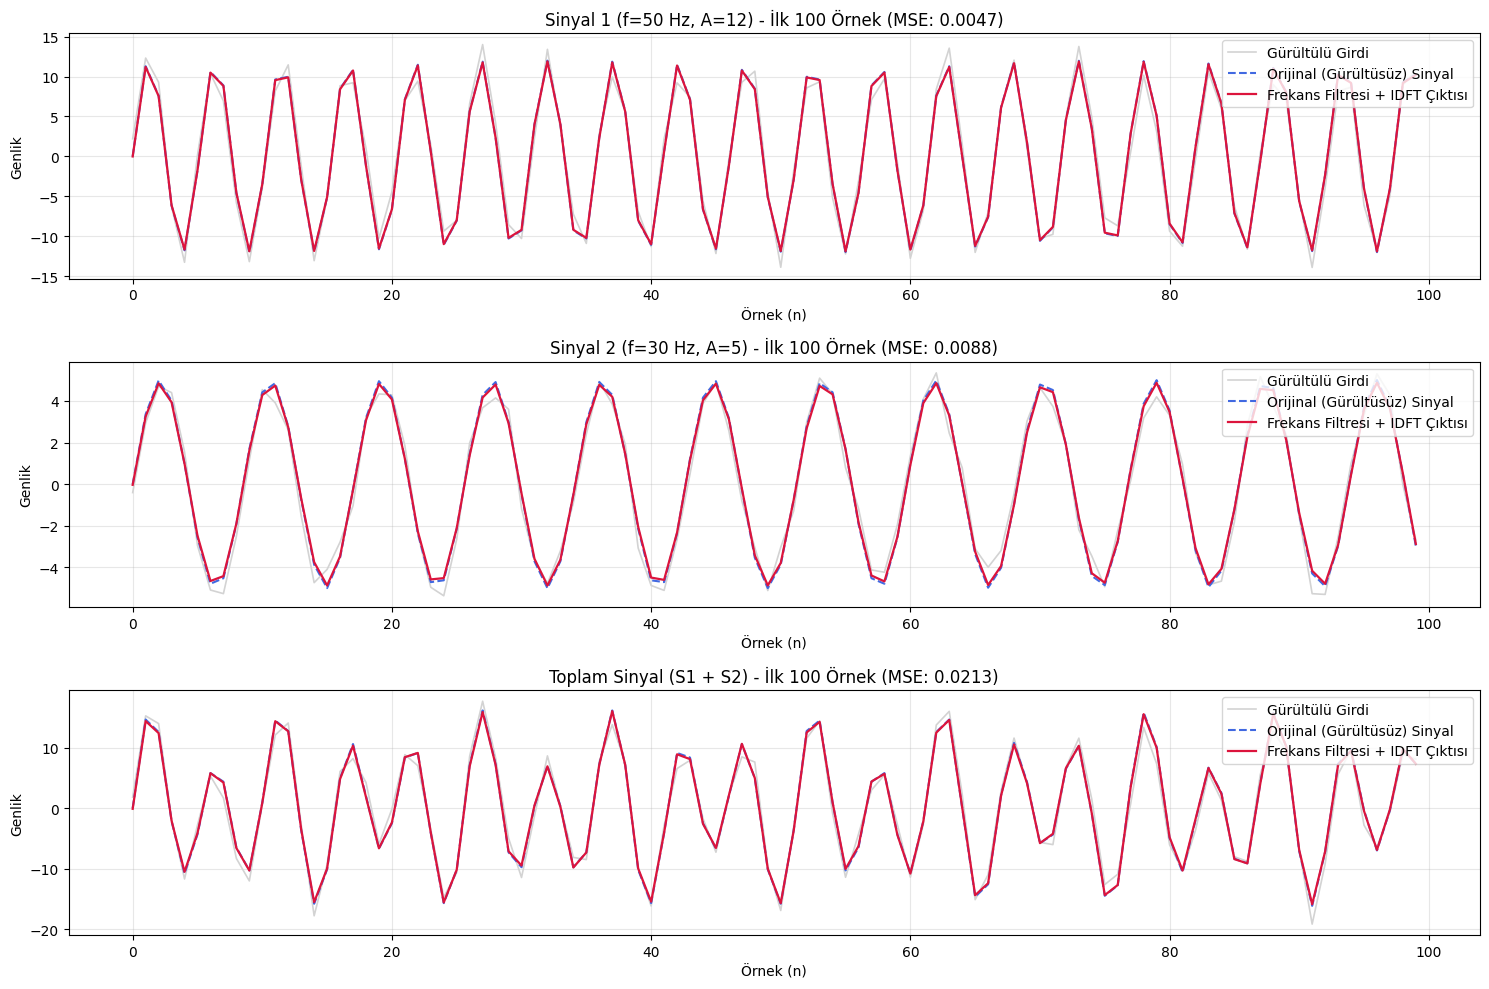

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def doldur_sinus(vec, amplitude=1.0, frequency=5.0, phase=0.0, fs=256.0):
    n = len(vec)
    if n <= 0 or (n & (n - 1)) != 0:
        raise ValueError("Vektör boyutu 2'nin kuvveti olmalıdır.")
    t = np.arange(n, dtype=np.float64) / fs
    vec[:] = amplitude * np.sin(2.0 * np.pi * frequency * t + phase)
    return vec

def gurultu_ekle(vec, noise_ratio):
    if not (0.0 <= noise_ratio <= 1.0):
        raise ValueError("Gürültü oranı [0, 1] aralığında olmalıdır.")
    vec_arr = np.asarray(vec, dtype=np.float64)
    peak_amp = np.max(np.abs(vec_arr))
    if peak_amp == 0:
        peak_amp = 1.0
    noise = np.random.uniform(-1.0, 1.0, size=vec_arr.shape) * (noise_ratio * peak_amp)
    return vec_arr + noise

def dft_1d(vec, fs=256.0):
    x = np.asarray(vec, dtype=np.float64)
    N = len(x)
    if N <= 0 or (N & (N - 1)) != 0:
        raise ValueError("Vektör uzunluğu 2'nin kuvveti olmalıdır.")
    n = np.arange(N, dtype=np.float64).reshape((N, 1))
    k = np.arange(N, dtype=np.float64).reshape((1, N))
    dft_matrix = np.exp(-1j * 2.0 * np.pi * (n @ k) / N)
    harmonics = x @ dft_matrix
    magnitude = (np.abs(harmonics) / N) * 2.0
    magnitude[0] = np.abs(harmonics[0]) / N
    freqs = np.arange(N, dtype=np.float64) * (fs / N)
    return harmonics, magnitude, freqs

def idft_1d(harmonics):
    """
    Filtrelenmiş karmaşık harmonik vektöründen Ters DFT (IDFT) ile
    zaman uzayındaki sinyali yeniden üretir.
    """
    X = np.asarray(harmonics, dtype=np.complex128)
    N = len(X)
    n = np.arange(N, dtype=np.float64).reshape((N, 1))
    k = np.arange(N, dtype=np.float64).reshape((1, N))
    idft_matrix = np.exp(+1j * 2.0 * np.pi * (n @ k) / N)
    reconstructed = (X @ idft_matrix) / N
    return np.real(reconstructed)

def frekans_filtresi_esik(harmonics, threshold_ratio=0.25):
    """
    Harmonik vektöründe genliği (max genliğe göre oranlanan eşik değerin)
    altında kalan tüm harmonikleri sıfırlar.
    """
    H = np.asarray(harmonics, dtype=np.complex128).copy()
    N = len(H)
    # Gerçek genlik büyüklüğü
    amp_spectrum = np.abs(H) / N
    thresh = threshold_ratio * np.max(amp_spectrum)

    # Eşik değerin altındaki harmonikleri filtrele (sıfırla)
    mask = amp_spectrum < thresh
    H[mask] = 0.0
    return H, thresh

# 5. Görevdeki sinyallerin üretilmesi (N = 256, fs = 256 Hz)
N = 256
fs = 256.0
noise_ratio = 0.20

s1_clean = np.zeros(N, dtype=np.float64)
doldur_sinus(s1_clean, amplitude=12.0, frequency=50.0, phase=0.0, fs=fs)
s1_noisy = gurultu_ekle(s1_clean, noise_ratio)

s2_clean = np.zeros(N, dtype=np.float64)
doldur_sinus(s2_clean, amplitude=5.0, frequency=30.0, phase=0.0, fs=fs)
s2_noisy = gurultu_ekle(s2_clean, noise_ratio)

s_total_clean = s1_clean + s2_clean
s_total_noisy = s1_noisy + s2_noisy

cases = [
    ("Sinyal 1 (f=50 Hz, A=12)", s1_clean, s1_noisy),
    ("Sinyal 2 (f=30 Hz, A=5)", s2_clean, s2_noisy),
    ("Toplam Sinyal (S1 + S2)", s_total_clean, s_total_noisy),
]

plt.figure(figsize=(15, 10))

for idx, (label, clean_ref, noisy_in) in enumerate(cases):
    harm, mag, freqs = dft_1d(noisy_in, fs=fs)
    harm_filtered, used_thresh = frekans_filtresi_esik(harm, threshold_ratio=0.25)
    reconstructed = idft_1d(harm_filtered)

    # Yeniden üretilen sinyalin temiz referansa göre MSE değeri
    mse = np.mean((clean_ref - reconstructed) ** 2)
    print(f"{label} -> Eşik: {used_thresh:.3f} | Temiz Sinyale Göre MSE: {mse:.4f}")

    plt.subplot(3, 1, idx + 1)
    plt.plot(noisy_in[:100], label='Gürültülü Girdi', color='lightgray', linewidth=1.2)
    plt.plot(clean_ref[:100], '--', label='Orijinal (Gürültüsüz) Sinyal', color='royalblue', linewidth=1.5)
    plt.plot(reconstructed[:100], label='Frekans Filtresi + IDFT Çıktısı', color='crimson', linewidth=1.6)
    plt.title(f'{label} - İlk 100 Örnek (MSE: {mse:.4f})')
    plt.xlabel('Örnek (n)')
    plt.ylabel('Genlik')
    plt.legend(loc='upper right')
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()